# Exercise 1: Plotting functions

Consider the following function in one variable $x$, 
$$
f(x) = \sin(20 x) + 5 x^2
$$
which is the sum of the sine function and a quadratic function.

Perform the following tasks:

1.  Define a Python function that returns the function value $f(x)$ for some 
    argument $x$. The function should work with both scalar numbers and 
    NumPy arrays.

    *Hint:* The sine function is implemented in 
    [`np.sin()`](https://numpy.org/doc/stable/reference/generated/numpy.sin.html).

2.  Evaluate the function on a uniformly spaced grid of $x$-values
    on the interval $[-1, 1]$ using 51 grid points.

    Create a plot depicting the function on this interval. Set the
    $x$-ticks to the values $[-1, 0, 1]$ and add a legend.

3.  Locate the point $x_{min}$ where the function attains its minimum on the grid 
    you created and print the values $(x_{min}, f(x_{min}))$.

    *Hint:* You can use the NumPy function 
    [`np.argmin()`](https://numpy.org/doc/stable/reference/generated/numpy.argmin.html)
    for this.

4.  Augment the plot you created earlier with a horizontal and vertical
    line indicating where the minimum is located. Add a black dot at the point $(x_{min}, f(x_{min}))$.

    *Hint:* Horizontal and vertical lines can be added with 
    [`axhline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)
    and 
    [`axvline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axvline.html).
    A single dot can be added in various ways, e.g., using 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).

5.  Repeat the exercise but now use $N=501$ grid points to evaluate the function.

# Solution
### Part 1

In [86]:
import numpy as np
import matplotlib.pyplot as plt

def f (x):
    """Return function for given x"""
    f = np.sin(20*x) + 5*x**2
    return f


### part 2


Text(0.5, 1.0, 'f(x)')

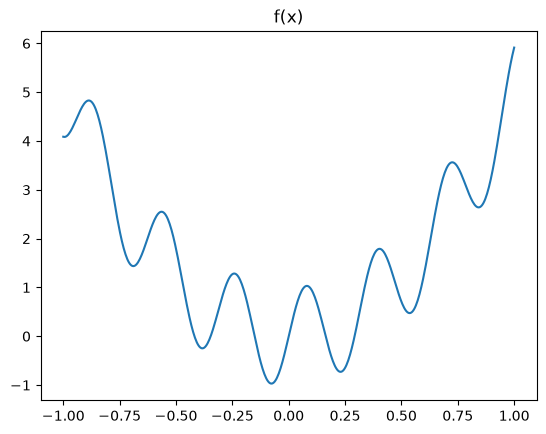

In [87]:
xvalues = np.linspace(-1,1,501)
yvalues = f(xvalues)

plt.plot(xvalues, yvalues, label="f(x)")
plt.title("f(x)")

### part 3

In [88]:
imin = np.argmin(yvalues)
xmin = xvalues[imin]
ymin = f(xmin)

print(f"{xmin:.2f}, {ymin:.2f}")

-0.08, -0.97


### part 4

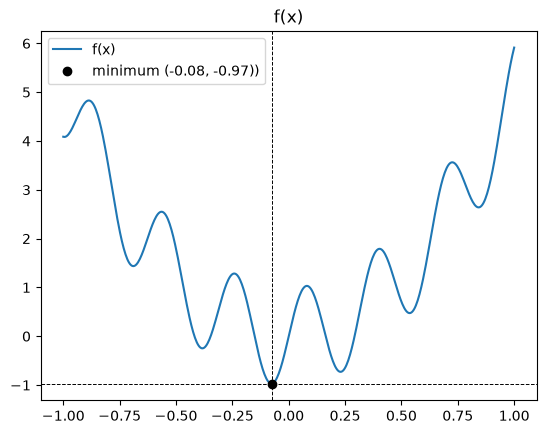

In [89]:
plt.plot(xvalues, yvalues, label="f(x)")
plt.title("f(x)")
plt.plot(xmin, ymin, "o", label="minimum (-0.08, -0.97))", c="black")
plt.legend()
plt.axvline(xmin, ls="--", lw=0.7, c="black")
plt.axhline(ymin, ls="--", lw=0.7,c="black")

***
# Exercise 2: Visualizing US business cycles and recessions

In this exercise, you are asked to plot two main business cycle indicators, GDP growth and the unemployment rate, for the United States.

1.  Load the data from the CSV file `FRED/FRED_quarterly.csv` located in the repository's `data` folder.

    Familiarize yourself with the data by printing the columns present in the data set and the first 5 rows of data.

    *Hint:* Use 
    [`read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    with `parse_dates=['DATE']` and `index_col='DATE'` to automatically parse strings stored in the `DATE` column as dates and set `DATE` as the index.

2.  Compute the quarterly GDP growth (i.e., the relative change of the column `GDP` vs. the previous quarter) in percent.

    *Hint:* This can be achieved using the 
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    method.

3.  Create a figure with two subplots (arranged in 2 rows) which show the GDP growth and the unemployment rate.

    *Hint:* You can construct the graph either using Matplotlib's plotting function or using pandas's 
    [`DataFrame.plot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html)
    method.

4.  You want to understand how the business cycle indicators behave around
    recession starts in the US. The National Bureau of Economic Research (NBER)
    is a research organization that dates US business cycles.

    The `peak` column records the month immediately before each recession starts.

    1.  Load the business cycle dates from `NBER_cycle_dates.csv` located in the
        `data/` folder.

        Drop all rows where the `peak` date is before 1948.

        *Hint:* Use `pd.read_csv(..., parse_dates=['peak', 'trough'])` to
        automatically parse strings in the `peak` and `trough` columns.

    2.  Loop through all remaining business cycle peak dates and add a vertical
        line to each of the two subplots for GDP growth and unemployment at each
        date. These lines mark the months immediately before recession starts.

    3.  Can you detect any patterns for GDP growth and the unemployment rate
        around recession starts?

# Solution

### Part 1

In [90]:
import pandas as pd

DATA_PATH = '../../data'
file = f"{DATA_PATH}/FRED/FRED_quarterly.csv"
df = pd.read_csv(file, parse_dates=["DATE"], index_col=["DATE"])
df.head(3)

,Year,Quarter,GDP,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
DATE,,,,,,,,
1948-01-01,1948,1,2239.7,23.7,3.4,NaN,NaN,58.6
1948-04-01,1948,2,2276.7,23.8,3.9,NaN,NaN,59.0
1948-07-01,1948,3,2289.8,24.4,3.6,NaN,NaN,59.3


#### Part 2

In [91]:
df["GDP_growth"] = df["GDP"].pct_change()*100


#### Part 3

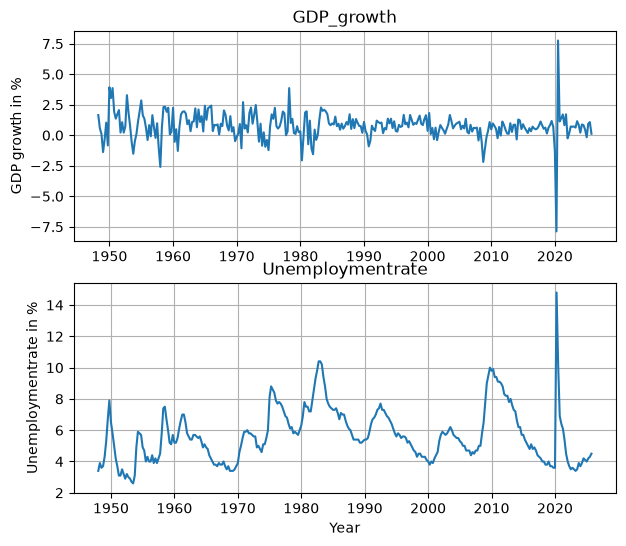

In [92]:
df["GDP_growth"] = df["GDP"].pct_change()*100

fig, axes = plt.subplots(2, 1, sharex=False, sharey=False, figsize=(7, 6.0))

axes[0].plot(df["GDP_growth"])
axes[0].set_title("GDP_growth")
axes[0].set_ylabel("GDP growth in %")
axes[0].grid()
axes[1].plot(df["UNRATE"])
axes[1].set_title("Unemploymentrate")
axes[1].set_ylabel("Unemploymentrate in %")
axes[1].set_xlabel("Year")
axes[1].grid()




#### part 4

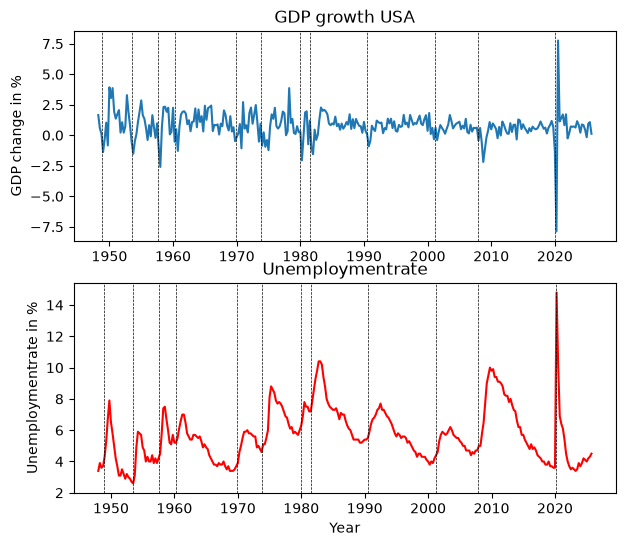

In [93]:
file = f"{DATA_PATH}/NBER_cycle_dates.csv"

df_NBER = pd.read_csv(file, parse_dates=['peak', 'trough'])
df_1948 = df_NBER.query('peak >= "1948-01-01"')

fig, axes = plt.subplots(2, 1, figsize=(7, 6.0))

axes[0].plot(df["GDP_growth"])
axes[0].set_title("GDP growth USA")
axes[0].set_ylabel("GDP change in %")
axes[1].plot(df["UNRATE"], c="r")
axes[1].set_title("Unemploymentrate")
axes[1].set_ylabel("Unemploymentrate in %")
axes[1].set_xlabel("Year")

#loop that plots a dashed line that marks the start of recession periods
for date in df_1948["peak"]:
    axes[0].axvline(date, ls="--", lw="0.5", c="black")
    axes[1].axvline(date, ls="--", lw="0.5", c="black")


***
# Exercise 3: Daily returns of US stock market indices

In this exercise, we examine how the three major US stock market indices performed in 2025.
Use the data in `indices.csv` from the folder `../../data/stockmarket` to solve the following tasks:

1.  Load the CSV data and restrict the sample to the calendar year 2025. 

    *Hint:* The data is tab-separated, so you need to specify `sep='\t'` when reading in the data.

    *Hint:* You should use 
    [`read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    with `parse_dates=['Date']` to automatically parse strings stored in the `Date` column as dates.

2.  The data comes in a "long" format where each date-ticker combination is stored in 
    a separate row. For the following analysis, the data needs to be reshaped such that each 
    ticker symbol is in its own column ("wide" format).

    Use the 
    [`pivot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html)
    method to reshape the `DataFrame` into the desired form. Consult the 
    [user guide](https://pandas.pydata.org/docs/user_guide/reshaping.html#pivot-and-pivot-table)
    to see a graphical illustration.

    Your pivoted `DataFrame` should look as follows:
    
    |    Ticker	 |   DJIA    | NASDAQ  |  SP500 |
    |------------|-----------|---------|--------|
    | Date		 |           |	       |        |
    | 2025-01-02 |	42392.3	 | 19280.8 | 5868.5 |
    | 2025-01-03 |  42732.1	 | 19621.7 | 5942.5 |
    
3.  Create a line plot which shows the time series for each of the three ticker symbols in a single graph,
    for example using 
    [`DataFrame.plot()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html).
4.  The graph you just created is not very satisfactory as the three
    indices are recorded on vastly different scales. Express each index
    relative to its initial value in 2025 (so that all three start with the value
    1.0) and recreate the previous graph with this normalized data.
5.  Another way to check whether the three indices are co-moving is to compute and plot their daily returns.
    For each index, compute the daily returns, i.e., the relative change vs. the previous closing price in percent (e.g., using 
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)), 
    and plot the three time series of daily returns in a single graph.
6.  The previous plots suggest that the three indices co-move a lot. 
    
    1.  In order to quantify the strength of 
        this co-movement, compute the pairwise correlations of daily returns using 
        [`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).

    2.  Create a figure with 3-by-3 subplots where each off-diagonal plot shows the 
        scatter plot for two of the indices.
    
        *Hint:* You can use the function 
        [`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
        to accomplish this task. Alternatively, you can create a figure with 3-by-3 subplots using Matplotlib's 
        [`subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html),
        iterate over all rows and columns and add a 
        [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)
        plot to each `axes` object.

    3.  Add the correlation coefficient for each stock market index pair 
        as text to the corresponding subplot in the figure you created
        (this can be done using 
        [`text()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.text.html)).

# Solution

#### Part 1

In [94]:
import pandas as pd
import numpy as np

#Defining dataframe as values after 2025
file = "../../data/stockmarket/indices.csv"
df = pd.read_csv(file, sep="\t", parse_dates=["Date"])
df = df.query("Date >= 2025")

#Resetting the indexes so 2025 because the new index 0
df = df.reset_index(drop=True)

df.head(3)

,Date,Ticker,Price
0,2025-01-02,DJIA,42392.3
1,2025-01-02,SP500,5868.5
2,2025-01-02,NASDAQ,19280.8


### Part 2

In [95]:

df = df.pivot(index = "Date", columns="Ticker", values="Price")
df.head(5)

Ticker,DJIA,NASDAQ,SP500
Date,,,
2025-01-02,42392.3,19280.8,5868.5
2025-01-03,42732.1,19621.7,5942.5
2025-01-06,42706.6,19865.0,5975.4
2025-01-07,42528.4,19489.7,5909.0
2025-01-08,42635.2,19478.9,5918.2


#### Part 3

Text(0.5, 0, 'Date')

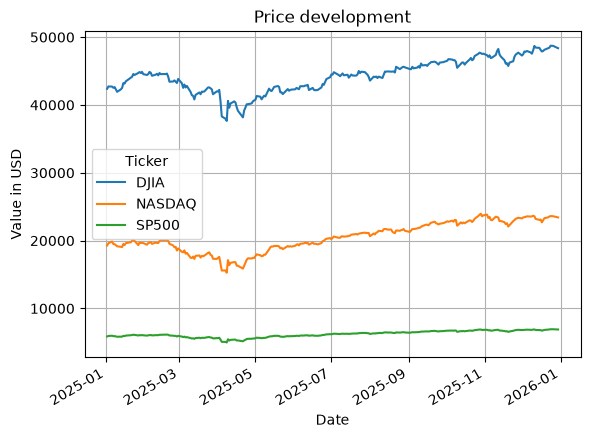

In [96]:
import matplotlib.pyplot as plt

_=df.plot.line()
plt.grid()
plt.title("Price development")
plt.ylabel("Value in USD")
plt.xlabel("Date")

#### Part 4

Text(0.5, 0, 'Date')

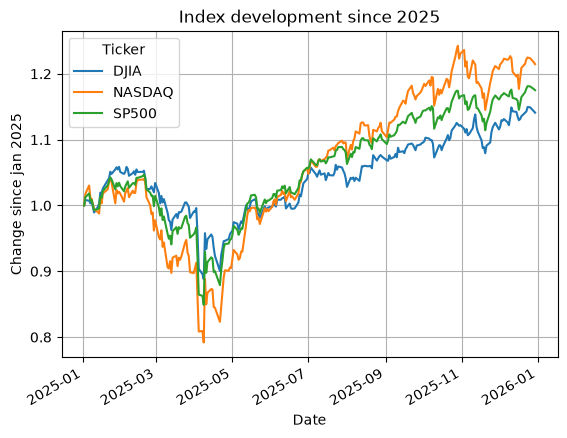

In [97]:
#Make a new dataframe which is the dataframe devided by the index 0 values in the orginal dataframe. 
df_norm = df/df.iloc[0]

#plot the new dataframe
df_norm.plot.line()
plt.grid()
plt.title("Index development since 2025")
plt.ylabel("Change since jan 2025")
plt.xlabel("Date")


#### Part 5

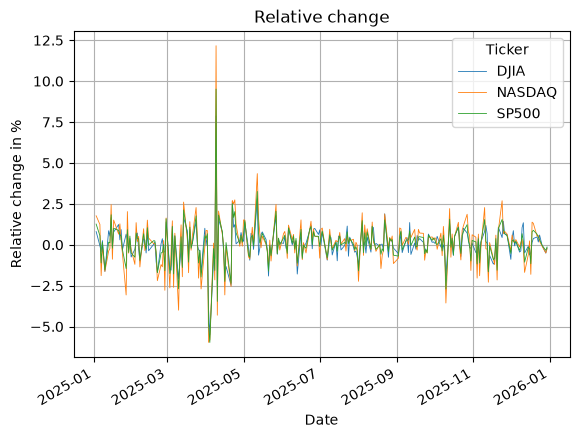

In [98]:
#Defining new dataframe using pct_change
df_relative = df.pct_change()*100

#plotting the dataframe
df_relative.plot.line(ylabel="Relative change in %", title="Relative change", lw=0.6)
plt.grid()

#### Part 6
The previous plots suggest that the three indices co-move a lot.     
1.  In order to quantify the strength of 
    this co-movement, compute the pairwise correlations of daily returns using 
    [`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).
2.  Create a figure with 3-by-3 subplots where each off-diagonal plot shows the 
    scatter plot for two of the indices.
    
*Hint:* You can use the function 
     [`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
    to accomplish this task. Alternatively, you can create a figure with 3-by-3 subplots using Matplotlib's 
    [`subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html),        iterate over all rows and columns and add a 
   [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) 
    plot to each `axes` object.

3.  Add the correlation coefficient for each stock market index pair 
        as text to the corresponding subplot in the figure you created
        (this can be done using 
        [`text()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.text.html)).

In [99]:
from pandas.plotting import scatter_matrix

df_corr = df.corr()
df_corr

# Create figure with 3x3 scatter plots. Main diagonal shows kernel density
# for each index.
axes = scatter_matrix(
    df_returns,
    figsize=(6, 6),
    alpha=0.9,
    c='none',
    edgecolors='steelblue',
    diagonal='kde',
)

# Iterate over subplots, add correlation text to each off-diagonal panel
for i in range(axes.shape[0]):
    for j in range(axes.shape[1]):
        # Skip diagonal panels, correlation is 1.0 by construction
        if i == j:
            continue
        # Reference to current Axes object (subplot)
        ax = axes[i, j]
        c = df_corr.iloc[i, j]
        ax.text(
            0.95,
            0.05,
            f'Correlation: {c:.3f}',
            transform=ax.transAxes,
            va='bottom',
            ha='right',
        )

NameError: name 'df_returns' is not defined

***
# Exercise 4: Population and electric cars in Norway

How do Norwegian municipalities differ in population size, population density,
and the use of electric cars? Use the data in
`../../data/ssb/municipalities.csv` to explore these questions.

The file contains one row per municipality. The variables needed here are:

- `municipality`: Municipality name.
- `population`: Number of residents.
- `land_area`: Land area in square kilometers, excluding freshwater.
- `cars`: Number of registered passenger cars, including electric cars.
- `electric_cars`: Number of electric passenger cars, excluding hybrids.

The data come from Statistics Norway (SSB); see the
[data description](../../data/ssb/README.md) for details.

1.  Load the variables listed above into a `DataFrame`. Display the first
    five rows and count the municipalities. Are any of the population, land
    area, or car counts missing?

    *Hint:* Use the `usecols` argument of
    [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    to select columns, and
    [`DataFrame.info()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)
    with `show_counts=True` to inspect the number of nonmissing observations.

2.  Create a new column `pop_density` containing population divided by land area.
    This measures residents per square kilometer.

    Create a figure with two histograms arranged in one row: population size
    and population density. Use 30 bins in each histogram.
    Express population in thousands and label both axes.

    *Hint:* Use `plt.subplots(1, 2)` and the
    [`hist()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)
    method of each `Axes` object. The height of each bar should show the
    number of municipalities in that bin.

3.  Compute the percentage of passenger cars that are electric in each
    municipality as `100 * electric_cars / cars`, and store it in a new
    column `ev_share`.

    Create a second figure with two histograms arranged in one row: the
    number of electric cars (in thousands) and the EV share (in percent).
    Again, use 30 bins and label both axes.

    How do these distributions differ? Why might the EV share be more useful
    than the number of electric cars when comparing municipalities?

4.  Create a scatter plot with population density on the horizontal axis and
    the EV share (in percent) on the vertical axis. Use one equally sized
    point per municipality and some transparency to make overlapping points
    easier to see.

    Describe the relationship between population density and the EV share.

5.  **[Advanced]** Recreate the scatter plot with a logarithmic
    horizontal axis. Keep the EV share on its original percentage scale.

    *Hint:* Use
    [`set_xscale()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xscale.html)
    with `'log'`. Equal distances on this axis represent equal ratios:
    moving from 1 to 10 residents per square kilometer takes the same space
    as moving from 10 to 100.

    Why is this plot easier to read?

## Solution
#### Part 1

In [ ]:
import pandas as pd

file = "../../data/ssb/municipalities.csv"
df = pd.read_csv(file, usecols=['municipality', 'population', 'land_area', 'cars', 'electric_cars'])
df.info(show_counts=True)
#We se that there are 357 municipalities and none are missing data.

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   municipality   357 non-null    str  
 1   population     357 non-null    int64
 2   land_area      357 non-null    int64
 3   cars           357 non-null    int64
 4   electric_cars  357 non-null    int64
dtypes: int64(4), str(1)
memory usage: 14.1 KB


#### Part 2

In [ ]:
df["pop_density"] = df["population"]/df['land_area']
df.head()

,municipality,population,land_area,cars,electric_cars,pop_density
0,Oslo,724290,426,246809,120469,1700.211268
1,Bergen,293709,445,122239,60695,660.020225
2,Trondheim - Tråante,216518,496,92529,37742,436.528226
3,Stavanger,150123,256,69615,27663,586.417969
4,Bærum,132358,189,78279,38369,700.306878


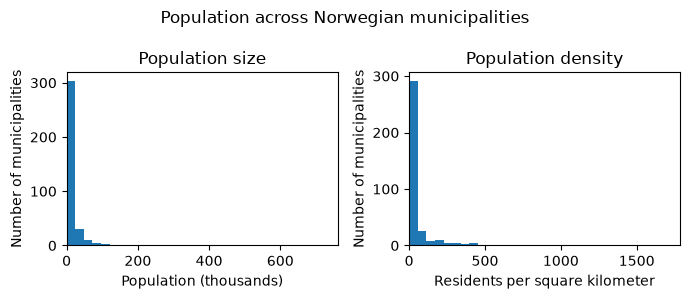

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,2, figsize=(7,3))

axes[0].hist(df['population'] / 1000, bins=30)
axes[0].set_title('Population size')
axes[0].set_xlabel('Population (thousands)')
axes[0].set_ylabel('Number of municipalities')
axes[0].set_xlim(left=0)

axes[1].hist(df["pop_density"], bins=30)
axes[1].set_title('Population density')
axes[1].set_xlabel('Residents per square kilometer')
axes[1].set_ylabel('Number of municipalities')
axes[1].set_xlim(0)

fig.suptitle('Population across Norwegian municipalities')
fig.tight_layout()

#### Part 3

In [ ]:
df["EV_share(%)"] = 100 * df["electric_cars"] / df["cars"]
df.head()

,municipality,population,land_area,cars,electric_cars,pop_density,EV_share(%)
0,Oslo,724290,426,246809,120469,1700.211268,48.810619
1,Bergen,293709,445,122239,60695,660.020225,49.652729
2,Trondheim - Tråante,216518,496,92529,37742,436.528226,40.789374
3,Stavanger,150123,256,69615,27663,586.417969,39.737126
4,Bærum,132358,189,78279,38369,700.306878,49.015700


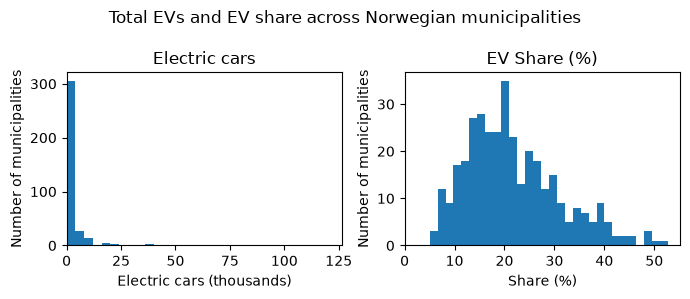

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(7,3))

axes[0].hist(df['electric_cars'] / 1000, bins=30)
axes[0].set_title('Electric cars')
axes[0].set_xlabel('Electric cars (thousands)')
axes[0].set_ylabel('Number of municipalities')
axes[0].set_xlim(left=0)

axes[1].hist(df["EV_share(%)"], bins=30)
axes[1].set_title('EV Share (%)')
axes[1].set_xlabel('Share (%)')
axes[1].set_ylabel('Number of municipalities')
axes[1].set_xlim(0)

fig.suptitle('Total EVs and EV share across Norwegian municipalities')
fig.tight_layout()

#### Part 4

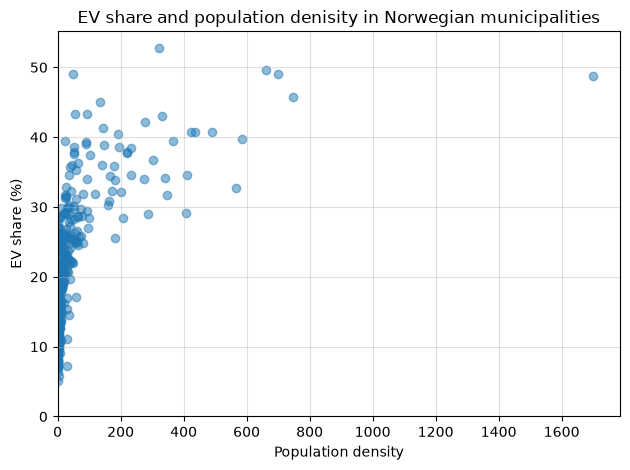

In [ ]:
plt.scatter(df["pop_density"], df["EV_share(%)"], alpha=0.5)
plt.xlabel("Population density")
plt.ylabel("EV share (%)")
plt.title("EV share and population denisity in Norwegian municipalities")
plt.ylim(0)
plt.xlim(0)
plt.grid(alpha=0.4)
plt.tight_layout()

#### Part 5


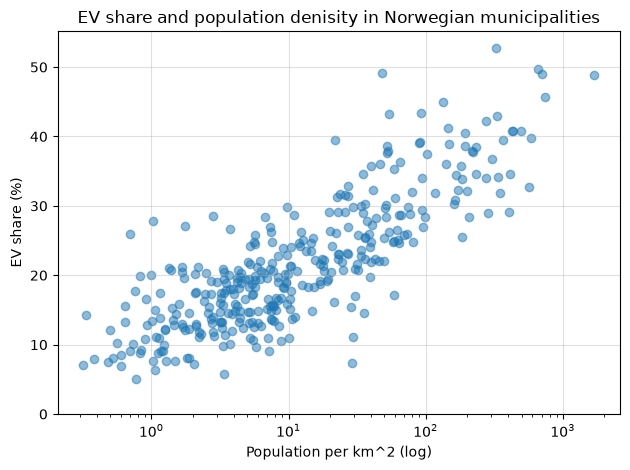

In [ ]:
plt.scatter(df["pop_density"], df["EV_share(%)"], alpha=0.5)
plt.xlabel("Population per km^2 (log)")
plt.ylabel("EV share (%)")
plt.title("EV share and population denisity in Norwegian municipalities")
plt.ylim(0)
plt.grid(alpha=0.4)
plt.xscale("log")
plt.tight_layout()

***
# Exercise 5: Cruise ship arrivals in Bergen

How do cruise ship arrivals in Bergen vary over time and across seasons?
Use `kystverket/bergen_monthly_calls.csv` in the repository's `data/` folder
to explore these questions.

The file contains monthly arrival counts by vessel type. The variables needed
here are:

- `month`: Arrival month, stored as `YYYY-MM`.
- `vessel_type`: Detailed vessel type.
- `calls`: Monthly aggregate number of reported arrivals, including repeat visits
  by the same ship.

The cruise category also includes some coastal service vessels. The data come
from Kystverket; see the
[data description](../../data/kystverket/README.md) for details.

1.  Load the CSV file into a `DataFrame`. Display the first five rows and
    determine the sample period.

    *Hint:* Use
    [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
    with `parse_dates=['month']` and `date_format='%Y-%m'` to parse the dates.
    Each month will be represented by its first day.

2.  Select observations with `vessel_type` equal to `'Passenger/Cruise'`.
    Restrict the sample to the complete calendar years **2013–2025**.
    Set `month` as the index and sort chronologically. Use this selection
    for all remaining parts.

    *Hint:* After parsing `month` as a datetime column, you can compare it
    directly with date strings. For example,
    `df_calls['month'] >= '2013-01-01'` selects observations on or after
    January 1, 2013. Combine two comparisons to select the required date range.

3.  Create a line plot of monthly cruise ship arrivals over the selected sample.
    Label both axes and add a title. Find the month with the most arrivals,
    print the month and its arrival count, and indicate the month with a vertical
    line in the plot.
    Describe the seasonal pattern and the changes visible around 2020–2021.

    *Hint:* The
    [`idxmax()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.idxmax.html)
    method returns the index label of the first maximum.

4.  Compute the average number of arrivals for each calendar month using a loop.
    For each month from January through December, select the corresponding
    observations, compute the mean of `calls`, and append it to a list.

    Create a bar chart of the 12 averages, with month names on the horizontal
    axis. Which months have the most arrivals on average?

    *Hint:* Loop over `range(1, 13)`. The `df_cruise.index.month` attribute
    gives the calendar month (1 for January through 12 for December) of each
    observation.

# Solution

### Part 1

In [100]:
import pandas as pd
DATA_PATH = '../../data'
file = f"{DATA_PATH}/kystverket/bergen_monthly_calls.csv"

df = pd.read_csv(file, parse_dates=["month"], date_format="%Y-%m")


### Part 2

In [101]:
dmin = df["month"].min()
dmax = df["month"].max()
#print(f"Sample period: {dmin} - {dmax}")

df_cruise = df.query(
    'vessel_type  == "Passenger/Cruise" & month >= "2013-01-01" & month < "2026-01-01"'
    )
df_cruise = df_cruise.set_index("month")
df_cruise

,vessel_type,vessel_category,calls
month,,,
2013-01-01,Passenger/Cruise,Passenger ships,0
2013-02-01,Passenger/Cruise,Passenger ships,4
2013-03-01,Passenger/Cruise,Passenger ships,4
2013-04-01,Passenger/Cruise,Passenger ships,5
2013-05-01,Passenger/Cruise,Passenger ships,48
...,...,...,...
2025-08-01,Passenger/Cruise,Passenger ships,64
2025-09-01,Passenger/Cruise,Passenger ships,45
2025-10-01,Passenger/Cruise,Passenger ships,33


#### Part 3

In [102]:
#find the month with the most arrivals
peak_month = df_cruise["calls"].idxmax()
peak = df_cruise.loc[peak_month, "calls"]

# The :%Y thing is just date formating. It works without it
print(f"The amount of arrivals peaked {peak_month:%B %Y} with {peak} arrivals")

The amount of arrivals peaked June 2017 with 90 arrivals


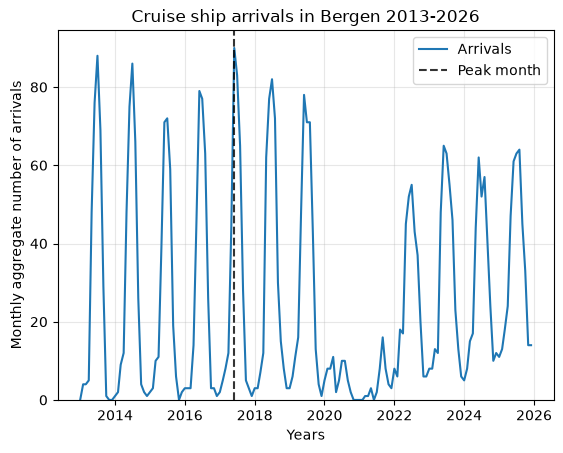

In [103]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.plot(df_cruise.index, df_cruise["calls"], label="Arrivals")
ax.axvline(peak_month,ls="--", c="black", alpha=0.8, label="Peak month")
ax.legend()
ax.set_title("Cruise ship arrivals in Bergen 2013-2026")
ax.set_xlabel("Years")
ax.set_ylabel("Monthly aggregate number of arrivals")
ax.set_ylim(0)
ax.grid(alpha=0.3)

#### Part 4

In [117]:
monthly_average= []
months = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "okt", "nov", "des"]

for i in range (1,13):
    df_month = df_cruise[df_cruise.index.month == i]
    monthly_average.append(df_month["calls"].mean())

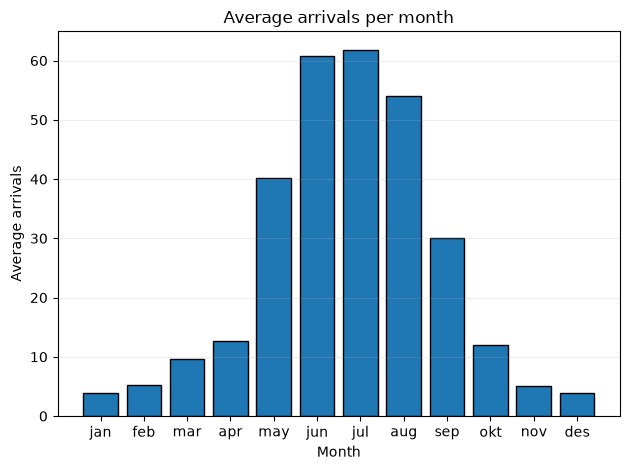

In [122]:
plt.bar(months, monthly_average, ec="black")
plt.title("Average arrivals per month")
plt.ylabel("Average arrivals")
plt.xlabel("Month")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()